# Single Fidelity Surrogate Model Comparison

This workbook is aimed at testing the convergence of single fidelity models to data sets taken from analytical functions. The goal is to show how the functions increase in accuracy as the number of samples increase.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from SurrogateModels import mfsnn
from torch import nn as tnn

The following creates some scaffolding for systematically creating and assessing kriging models.

In [2]:
import time
import csv


def create_test_points(func: mfs.MultiFidelityTemplate, n=2000):
    # Create a set of samples to create a ground truth
    X_test = func.sample_random(n)
    y_test = func.high_fidelity(X_test)
    return X_test, y_test


def generate_nn_model(
    name,
    func: mfs.MultiFidelityTemplate,
    n,
    seed,
    X_test,
    y_test,
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-4,
    weight_decay=1e-6,
    activation=tnn.Tanh(),
    epochs=1000,
    x_transform=True,
    bounds=None,
):
    X_train = func.sample_random(n, seed=seed)
    # X_train = func.sample_uniform(n)
    y_train = func.high_fidelity(X_train)
    print(f"y mean = {y_train.mean()}")
    
    print(f"y max = {y_train.max()}")
    training_data = zip(X_train, y_train)
    with open("training_data.txt", "w") as file:
        for row in training_data:
            file.write(f"{row[0].tolist()},{row[1].tolist()}\n")
    # Setup timer to gauge model training time
    t0 = time.perf_counter()
    model = mfsnn.MLPNetwork(
        X=X_train,
        y=y_train,
        X_test=X_test,
        y_test=y_test,
        activation=activation,
        hidden_layer_size=hidden_layer_size,
        epochs=epochs,
        learning_rate=learning_rate,
        weight_decay=weight_decay,
        scale_input=x_transform,
        bounds = bounds,
        scale_output=True,
        y_scale_method="standard"
    )
    model_training_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    error = model.model_error(X_test, y_test)
    evaluation_time = time.perf_counter() - t0
    print(
        f"Run {name} :: seed {seed} :: points {n} :: error {error} :: train_time {model_training_time} :: evaluation_time {evaluation_time}"
    )
    return model, error, model_training_time, evaluation_time


def generate_model_comparisons(
    name,
    func: mfs.MultiFidelityTemplate,
    X_test,
    y_test,
    sample_low=5,
    sample_high=105,
    step_size=5,
    seeds=5,
    points=[],
    model_error=[],
    training_time=[],
    evaluation_time=[],
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-4,
    output_file="model_comparison_output.csv",
):
    # Generate a Kriging model of the data and test accuracy using a number of random sample points
    n_points = list(range(sample_low, sample_high, step_size))
    for seed in range(0, seeds):
        for n in n_points:
            X_train = func.sample_random(n, seed=seed)
            # X_train = func.sample_uniform(n)
            y_train = func.high_fidelity(X_train)
            # Setup timer to gauge model training time
            t0 = time.perf_counter()

            model = mfsnn.MLPNetwork(
                X=X_train,
                y=y_train,
                X_test=X_test,
                y_test=y_test,
                activation=tnn.Tanh(),
                hidden_layer_size=hidden_layer_size,
                epochs=15000,
                learning_rate=learning_rate,
                weight_decay=1e-6,
                bounds = func.bounds,
                scale_input=True,
                scale_output=True,
                y_scale_method="standard"
            )

            training_time.append(time.perf_counter() - t0)

            t0 = time.perf_counter()
            error = model.model_error(X_test, y_test)
            evaluation_time.append(time.perf_counter() - t0)
            model_error.append(model.model_error(X_test, y_test))
            points.append(n)
            print(
                f"Run {name} :: seed {seed} :: points {n} :: error {error} :: train_time {training_time[-1]} "
            )
            with open(output_file, "w", newline="") as file:
                writer = csv.writer(file)
                writer.writerow(
                    [
                        points[-1],
                        model_error[-1],
                        training_time[-1],
                        evaluation_time[-1],
                    ]
                )
    return points, model_error, evaluation_time, training_time


def plot_error_measure(
    points, error, name, color="blue", marker="o", label="Test", ax=None
):
    if ax == None:
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    ax.scatter(
        points,
        error,
        color=color,
        label=label,
        marker=marker,
    )
    ax.set_xlabel("Samples")
    ax.set_ylabel("RMS Error")
    ax.legend()
    ax.grid()
    ax.set_yscale("log")
    return ax


def export_to_csv(output_file, points, model_error, training_time, evaluation_time):
    with open(output_file, "w", newline="") as file:
        writer = csv.writer(file)
        for i, val in enumerate(points):
            writer.writerow(
                [
                    val,
                    model_error[i],
                    training_time[i],
                    evaluation_time[i],
                ]
            )

In [6]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

model, error, model_training_time, evaluation_time = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=0,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-3,
    weight_decay=0,
    activation=tnn.Tanh(),
    epochs=20000,
    x_transform=True,
    bounds=my_function.bounds,
)

y mean = 0.3288286537853353
y max = 7.957335392955316
tensor(0.9461, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.7850, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.6682, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.5327, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4775, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4154, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.3545, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.2851, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.2312, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1869, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1394, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0980, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0655, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0448, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0305, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0209, device='cuda:0', grad_fn=<MseLo

[0.9686350600443487, 0.9686350600443487, 0.9686350600443487, 0.9686350600443487, 0.9686350600443487, 0.9686350600443487, 0.9686350600443487, 0.9686350600443487, 0.9686350600443487, 0.9686350600443487, 0.9365278926102976, 0.9365278926102976, 0.9365278926102976, 0.9365278926102976, 0.9365278926102976, 0.9365278926102976, 0.9365278926102976, 0.9365278926102976, 0.9365278926102976, 0.9365278926102976, 0.9155128254057181, 0.9155128254057181, 0.9155128254057181, 0.9155128254057181, 0.9155128254057181, 0.9155128254057181, 0.9155128254057181, 0.9155128254057181, 0.9155128254057181, 0.9155128254057181, 0.9036791939124492, 0.9036791939124492, 0.9036791939124492, 0.9036791939124492, 0.9036791939124492, 0.9036791939124492, 0.9036791939124492, 0.9036791939124492, 0.9036791939124492, 0.9036791939124492, 0.898826879627305, 0.898826879627305, 0.898826879627305, 0.898826879627305, 0.898826879627305, 0.898826879627305, 0.898826879627305, 0.898826879627305, 0.898826879627305, 0.898826879627305, 0.8968429

<Axes3D: title={'center': 'Data'}, xlabel='x1', ylabel='x2', zlabel='f(x)'>

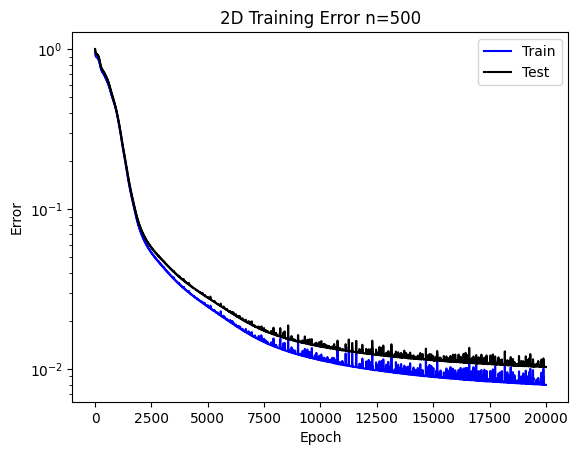

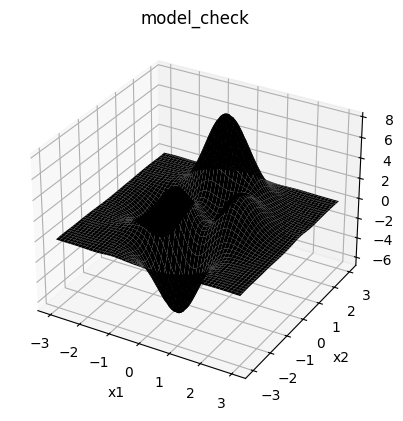

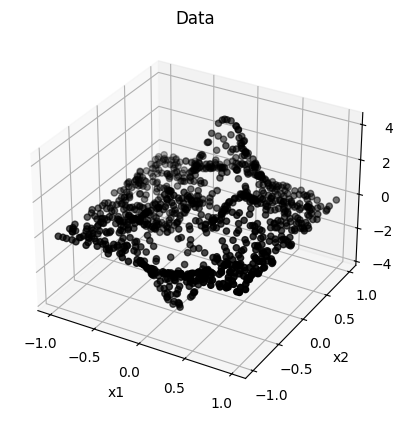

In [7]:
model.plot_training_error("2D Training Error n=500")
print(model.training_error)
model.plot_model(my_function.bounds,"model_check")
model.plot_data()

In [ ]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

points=[]
model_error=[]
training_time=[]
evaluation_time=[]
iterations = []
points, model_error, evaluation_time, training_time = generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=1000,
    step_size=100,
    seeds=3,    
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
    hidden_layer_size=[20,20,20],
    learning_rate=1e-3
)

### 4-Dimensional Dataset

In [16]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=5000)

model_30_30_10, error_30_30_10, model_training_time_30_30_10, evaluation_time_30_30_10 = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[30,30,10],
    learning_rate=1e-4,
    weight_decay=1e-4,
    activation=tnn.Tanh(),
    epochs=30000,
    x_transform=False,
    bounds=my_function.bounds,
)

y mean = 137.34520207423193
y max = 618.6308082190952
tensor(1.0431, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.8399, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.6854, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.5628, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4852, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4516, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4413, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4371, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4338, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4303, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4267, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4228, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4185, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4138, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4085, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.4024, device='cuda:0', grad_fn=<MseLo

[1.020132245765721, 1.020132245765721, 1.020132245765721, 1.020132245765721, 1.020132245765721, 1.020132245765721, 1.020132245765721, 1.020132245765721, 1.020132245765721, 1.020132245765721, 1.0082489369805576, 1.0082489369805576, 1.0082489369805576, 1.0082489369805576, 1.0082489369805576, 1.0082489369805576, 1.0082489369805576, 1.0082489369805576, 1.0082489369805576, 1.0082489369805576, 0.9967247254760183, 0.9967247254760183, 0.9967247254760183, 0.9967247254760183, 0.9967247254760183, 0.9967247254760183, 0.9967247254760183, 0.9967247254760183, 0.9967247254760183, 0.9967247254760183, 0.9855703634576992, 0.9855703634576992, 0.9855703634576992, 0.9855703634576992, 0.9855703634576992, 0.9855703634576992, 0.9855703634576992, 0.9855703634576992, 0.9855703634576992, 0.9855703634576992, 0.9747729575072541, 0.9747729575072541, 0.9747729575072541, 0.9747729575072541, 0.9747729575072541, 0.9747729575072541, 0.9747729575072541, 0.9747729575072541, 0.9747729575072541, 0.9747729575072541, 0.9643007

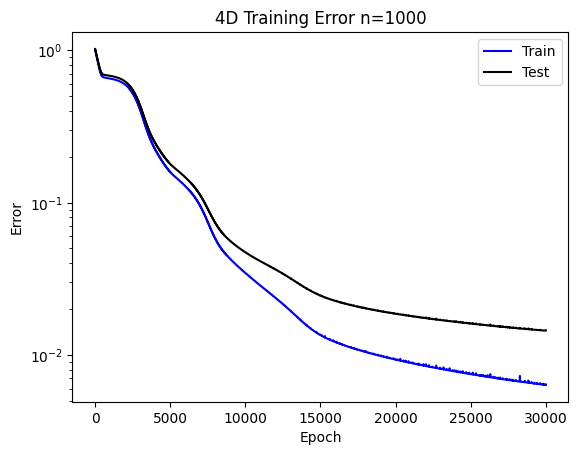

In [17]:
model_30_30_10.plot_training_error("4D Training Error n=1000")
print(model_30_30_10.training_error)
print(model_30_30_10.model_error(X_test,y_test))
model_30_30_10.plot_model(my_function.bounds,"model_check")
model_30_30_10.plot_data()

[172.969690038096, 172.969690038096, 172.969690038096, 172.969690038096, 172.969690038096, 172.969690038096, 172.969690038096, 172.969690038096, 172.969690038096, 172.969690038096, 172.84196742436427, 172.84196742436427, 172.84196742436427, 172.84196742436427, 172.84196742436427, 172.84196742436427, 172.84196742436427, 172.84196742436427, 172.84196742436427, 172.84196742436427, 172.71434825673865, 172.71434825673865, 172.71434825673865, 172.71434825673865, 172.71434825673865, 172.71434825673865, 172.71434825673865, 172.71434825673865, 172.71434825673865, 172.71434825673865, 172.5777677961446, 172.5777677961446, 172.5777677961446, 172.5777677961446, 172.5777677961446, 172.5777677961446, 172.5777677961446, 172.5777677961446, 172.5777677961446, 172.5777677961446, 172.4212909199441, 172.4212909199441, 172.4212909199441, 172.4212909199441, 172.4212909199441, 172.4212909199441, 172.4212909199441, 172.4212909199441, 172.4212909199441, 172.4212909199441, 172.23596754344024, 172.23596754344024,

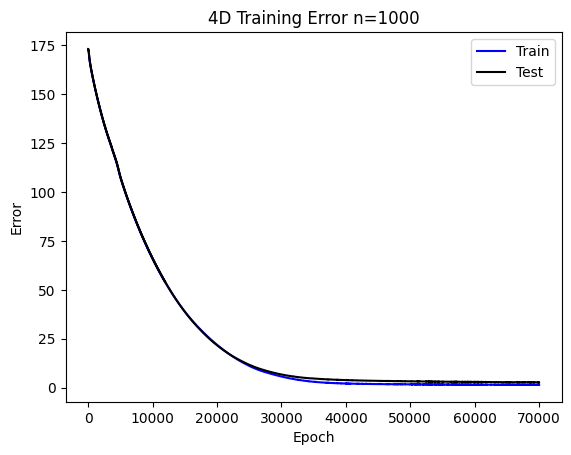

In [25]:
current_model = model_20_20_10
current_model.plot_training_error("4D Training Error n=1000")
print(current_model.training_error)
print(current_model.model_error(X_test,y_test))
current_model.plot_model(my_function.bounds,"model_check")
current_model.plot_data()

[172.8717857166837, 172.8717857166837, 172.8717857166837, 172.8717857166837, 172.8717857166837, 172.8717857166837, 172.8717857166837, 172.8717857166837, 172.8717857166837, 172.8717857166837, 172.70669229216335, 172.70669229216335, 172.70669229216335, 172.70669229216335, 172.70669229216335, 172.70669229216335, 172.70669229216335, 172.70669229216335, 172.70669229216335, 172.70669229216335, 172.52948117640648, 172.52948117640648, 172.52948117640648, 172.52948117640648, 172.52948117640648, 172.52948117640648, 172.52948117640648, 172.52948117640648, 172.52948117640648, 172.52948117640648, 172.32859464189337, 172.32859464189337, 172.32859464189337, 172.32859464189337, 172.32859464189337, 172.32859464189337, 172.32859464189337, 172.32859464189337, 172.32859464189337, 172.32859464189337, 172.0925384694961, 172.0925384694961, 172.0925384694961, 172.0925384694961, 172.0925384694961, 172.0925384694961, 172.0925384694961, 172.0925384694961, 172.0925384694961, 172.0925384694961, 171.81410284810732,

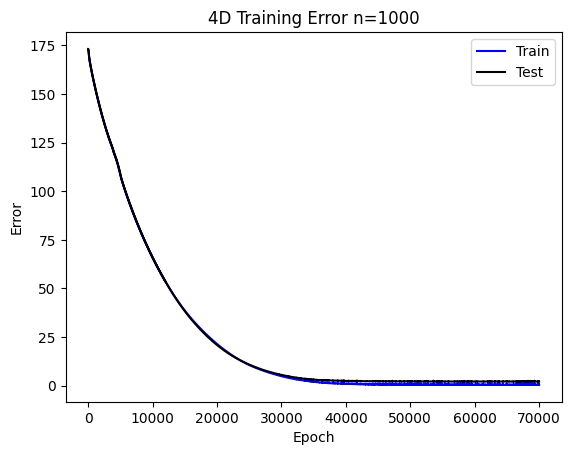

In [26]:
current_model = model_30_20_10
current_model.plot_training_error("4D Training Error n=1000")
print(current_model.training_error)
print(current_model.model_error(X_test,y_test))
current_model.plot_model(my_function.bounds,"model_check")
current_model.plot_data()

[172.98059184847878, 172.98059184847878, 172.98059184847878, 172.98059184847878, 172.98059184847878, 172.98059184847878, 172.98059184847878, 172.98059184847878, 172.98059184847878, 172.98059184847878, 172.85773594201677, 172.85773594201677, 172.85773594201677, 172.85773594201677, 172.85773594201677, 172.85773594201677, 172.85773594201677, 172.85773594201677, 172.85773594201677, 172.85773594201677, 172.7400164445112, 172.7400164445112, 172.7400164445112, 172.7400164445112, 172.7400164445112, 172.7400164445112, 172.7400164445112, 172.7400164445112, 172.7400164445112, 172.7400164445112, 172.61872612603477, 172.61872612603477, 172.61872612603477, 172.61872612603477, 172.61872612603477, 172.61872612603477, 172.61872612603477, 172.61872612603477, 172.61872612603477, 172.61872612603477, 172.48513296440942, 172.48513296440942, 172.48513296440942, 172.48513296440942, 172.48513296440942, 172.48513296440942, 172.48513296440942, 172.48513296440942, 172.48513296440942, 172.48513296440942, 172.33115

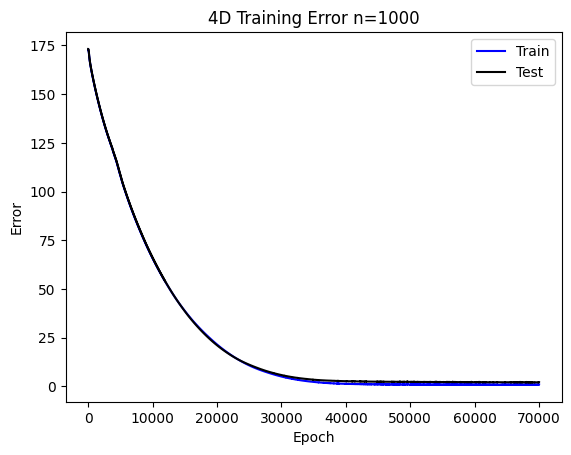

In [27]:
current_model = model_20_20_5
current_model.plot_training_error("4D Training Error n=1000")
print(current_model.training_error)
print(current_model.model_error(X_test,y_test))
current_model.plot_model(my_function.bounds,"model_check")
current_model.plot_data()

In [20]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=5000)

model, error, model_training_time, evaluation_time = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[20,20,10],
    learning_rate=1e-3,
    weight_decay=0,
    activation=tnn.Tanh(),
    epochs=100,
    x_transform=False,
    bounds=my_function.bounds,
)

y mean = 137.34520207423193
y max = 618.6308082190952
tensor(29890.5234, device='cuda:0', grad_fn=<MseLossBackward0>)
Run 4D :: seed 1 :: points 1000 :: error 170.50228775146203 :: train_time 3.1057454999536276 :: evaluation_time 0.0014521999983116984


In [19]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

points=[]
model_error=[]
training_time=[]
evaluation_time=[]
iterations = []
points, model_error, evaluation_time, training_time = generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=500,
    sample_high=2001,
    step_size=500,
    seeds=3,    
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
    hidden_layer_size=[20,20,20],
    learning_rate=1e-2
)

tensor(28915.5391, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(23193.2949, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(19225.5547, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(16334.6592, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(14276.6533, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(12862.3486, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(11930.2910, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(11344.4131, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(10994.8203, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(10797.6289, device='cuda:0', grad_fn=<MseLossBackward0>)
Run 4D :: seed 0 :: points 500 :: error 108.59631876561791 :: train_time 17.583443699986674 
tensor(31428.3340, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(25372.8320, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(21187.0820, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(18100.1777, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(1586

KeyboardInterrupt: 

In [14]:
key = "6D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

points=[]
model_error=[]
training_time=[]
evaluation_time=[]
iterations = []
points, model_error, evaluation_time, training_time = generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=500,
    sample_high=10000,
    step_size=500,
    seeds=3,    
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
    hidden_layer_size=[30,30,10],
    learning_rate=1e-3
)

tensor(1.0226, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.2946, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.2871, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.2784, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.2587, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.2022, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1027, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0231, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0072, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0049, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0041, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0036, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0032, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0029, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0026, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0023, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.0021, device='cuda:0', grad_fn=

In [17]:
report_name = "SingleFidelity6D_Cokriging_260924.csv"
print(model_error)
export_to_csv(
    report_name,
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
)

[0.15985666677495475, 0.09285770166874517, 0.07613967222342795, 0.0740089341597556, 0.06433052766570323, 0.05978344251630792, 0.06425636144891299, 0.06572081612954743, 0.06536803256013153, 0.05790335277108691, 0.06200814205134453, 0.04854929116010674, 0.06508326954288635, 0.06175073822747408, 0.05296520555289904, 0.05836607676473313, 0.05586788803703675, 0.06084862359046872, 0.0510131010935161, 0.13474327107147074, 0.08295375321878855, 0.07083258398328765, 0.06743693202741365, 0.07161058377060392, 0.06578825263986504, 0.05939155591989245, 0.06405020267586234, 0.057879015163875676, 0.05130334428645958, 0.058923891276146105, 0.06310117993715413, 0.06454047317694707, 0.0635848822038539, 0.0641782633229664, 0.06100723230491324, 0.05738676882657478, 0.06754163635729134, 0.059028607075699444, 0.12015771149249055, 0.08865427669162815, 0.06805622630580331, 0.0748842165239858, 0.06703660417484238, 0.06490413777729413, 0.06150393020088387, 0.06067934165381156, 0.05124702681839376, 0.055471940689